# Part 2 — experiments and selection history

This notebook organizes the complete working evidence by phase. It preserves
unsuccessful trials and separates local measurements from Kaggle feedback.
Full summary tables, split protocols, settings, manifests and figures are
included under `resources/experiments/`, along with the row predictions used
by these finalized comparisons. Other intermediate prediction arrays and
repeated fold audits remain in the working project and can be regenerated.
The original research notebooks are
under `resources/notebooks/`. The source appendix includes experiment and
figure-generation implementations, including the final files 11–16 sprint.

In [1]:
from pathlib import Path
import hashlib, json, os, runpy, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

locations = [candidate for base in [Path.cwd(), *Path.cwd().parents]
             for candidate in (base, base / "submission/midterm/part2", base / "midterm/part2")]
HANDIN = next(p for p in locations if (p / "01_final_model.ipynb").is_file())
ROOT = HANDIN / "resources"
assert (ROOT / "run.py").is_file(), "Run python part2/packaging/build_handin.py first, or extract the complete hand-in ZIP."
WORKSPACE = runpy.run_path(str(ROOT / "run.py"))["prepare_workspace"](ROOT)
sys.path.insert(0, str(WORKSPACE))
GENERATED = HANDIN / "generated"
GENERATED.mkdir(exist_ok=True)
sha256 = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
from experiments import load_data, metrics, PHASES
data = load_data()
SPRINT = ROOT / "experiments/leaderboard_sprint/runs/4dc0f274d45bce9e"
ledger = json.loads((ROOT / "submissions/leaderboard_results.json").read_text())
pd.set_option("display.max_rows", 16)
pd.set_option("display.max_columns", 12)


## Experiment inventory

Counts below are rows in the retained result tables. They are **not** a total
number of independent trained models: ensemble weights reuse predictions,
controls recur across phases, and one recipe is evaluated on multiple splits
and preprocessing tracks. The 318 component and 434 ensemble rows belong to
the initial search, not to the later common benchmark.

In [2]:
stages = {
    "Initial component search": "model_search/all_component_scores.csv",
    "Initial ensemble search": "model_search/ensemble_scores.csv",
    "Stack proposals and controls": "stack_improvements/runs/097ac8161372126d/strict/summary.csv",
    "Meta extensions and controls": "ani_extensions/meta/76d98f1d5e9d5ff1/strict/summary.csv",
    "Neighbor extensions and controls": "ani_extensions/neighbors/a27759052dfa9571/strict/summary.csv",
    "Files 01–10 on the common benchmark": "all_submissions/runs/8f68385e25e07615/comparison_strict.csv",
    "Sprint: 32 proposals plus controls": "leaderboard_sprint/runs/4dc0f274d45bce9e/summary_strict.csv",
    "Recent trees: 4 proposals plus controls": "leaderboard_sprint/recent_tree/dea847f57c7c07ee/summary_strict.csv",
    "Refinement: 19 proposals plus controls": "leaderboard_sprint/refine/2e5c792462013673/summary_strict.csv",
    "Final slot: 9 proposals plus controls": "leaderboard_sprint/finish/b235582538f63f9c/summary_strict.csv",
}
inventory = pd.DataFrame([dict(stage=stage, result_rows=len(pd.read_csv(ROOT / "experiments" / path)),
                               table=path) for stage, path in stages.items()])
display(inventory)
inventory.to_csv(GENERATED / "experiment_inventory.csv", index=False)
for stage, path in stages.items():
    display(Markdown(f"### {stage}"))
    display(pd.read_csv(ROOT / "experiments" / path))


,stage,result_rows,table
0,Initial component search,318,model_search/all_component_scores.csv
1,Initial ensemble search,434,model_search/ensemble_scores.csv
2,Stack proposals and controls,13,stack_improvements/runs/097ac8161372126d/stric...
3,Meta extensions and controls,22,ani_extensions/meta/76d98f1d5e9d5ff1/strict/su...
4,Neighbor extensions and controls,24,ani_extensions/neighbors/a27759052dfa9571/stri...
5,Files 01–10 on the common benchmark,13,all_submissions/runs/8f68385e25e07615/comparis...
6,Sprint: 32 proposals plus controls,39,leaderboard_sprint/runs/4dc0f274d45bce9e/summa...
7,Recent trees: 4 proposals plus controls,7,leaderboard_sprint/recent_tree/dea847f57c7c07e...
8,Refinement: 19 proposals plus controls,23,leaderboard_sprint/refine/2e5c792462013673/sum...
9,Final slot: 9 proposals plus controls,12,leaderboard_sprint/finish/b235582538f63f9c/sum...


### Initial component search

,name,family,representation,C,half_life,validation_phase_mean_logloss,...,depth,iterations,leaves,l2,variant,seed
0,text_wordwide_C2,text,wordwide,2.0,NaN,0.560582,...,NaN,NaN,NaN,NaN,NaN,NaN
1,catboost_d8_n600_none,catboost,NaN,NaN,NaN,0.572007,...,8.0,600.0,NaN,NaN,NaN,NaN
2,recency_criteria_C2_half6,recency,criteria,2.0,6.0,0.559664,...,NaN,NaN,NaN,NaN,NaN,NaN
3,recency_criteria_C2_half12,recency,criteria,2.0,12.0,0.560317,...,NaN,NaN,NaN,NaN,NaN,NaN
4,interactions_criteria_C2_weight0.3,interactions,criteria,2.0,NaN,0.560648,...,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,lr_metadata_year_C8_phase0.75,lr,metadata,8.0,NaN,0.690599,...,NaN,NaN,NaN,NaN,NaN,NaN
314,lr_metadata_year_C8_phase0,lr,metadata,8.0,NaN,0.692845,...,NaN,NaN,NaN,NaN,NaN,NaN
315,lr_knowledge_year_C8_phase1,lr,knowledge,8.0,NaN,0.690771,...,NaN,NaN,NaN,NaN,NaN,NaN
316,lr_metadata_none_C8_phase1,lr,metadata,8.0,NaN,0.755101,...,NaN,NaN,NaN,NaN,NaN,NaN


### Initial ensemble search

,name,n_components,validation_logloss,validation_I_logloss,validation_I_f1,validation_I_roc_auc,...,temporal_III_logloss,temporal_III_f1,temporal_III_roc_auc,temporal_III_pr_auc,temporal_phase_mean_logloss,joint_logloss
0,linear_mix_clinical0.25__catboost_deep__phases...,5,0.554559,0.559912,0.775281,0.789522,...,0.467493,0.869314,0.764221,0.900559,0.553285,0.552270
1,"linear_text__catboost_deep__phases0.25,0.5,0.75",4,0.554097,0.556890,0.777778,0.793015,...,0.468517,0.868497,0.762741,0.898821,0.554415,0.552321
2,linear_mix_clinical0.25__catboost_deep__phases...,5,0.554469,0.559912,0.775281,0.789522,...,0.467493,0.869314,0.764221,0.900559,0.554769,0.552982
3,linear_mix_clinical0.5__catboost_deep__phases0...,5,0.555702,0.564422,0.784091,0.780147,...,0.466588,0.871573,0.765037,0.902136,0.552993,0.553052
4,linear_mix_clinical0.25__catboost_deep__tree0.5,5,0.556053,0.567490,0.793103,0.779963,...,0.470224,0.873481,0.765599,0.899143,0.552578,0.553356
...,...,...,...,...,...,...,...,...,...,...,...,...,...
429,linear_baseline__lightgbm__tree0.75,2,0.581730,0.571803,0.728324,0.763051,...,0.503452,0.859599,0.718490,0.866347,0.578419,0.577304
430,linear_yearcap__lightgbm__tree0.75,2,0.581852,0.571946,0.716763,0.763235,...,0.501770,0.859786,0.717271,0.865378,0.578405,0.577367
431,catboost_recency,1,0.584550,0.624213,0.708075,0.741544,...,0.465733,0.872059,0.764498,0.901431,0.567097,0.578080
432,histgb,1,0.589224,0.623873,0.699387,0.716544,...,0.465878,0.874631,0.773372,0.907973,0.564335,0.578440


### Stack proposals and controls

... (11 outputs left out)

### Refinement: 19 proposals plus controls

,model,completed_splits,official,temporal,worst,cv,...,cv_delta,gap_mean_delta,gap_worst_delta,latest_delta,mean_time_delta,eligible
0,file10,10,0.557839,0.535890,0.587101,0.586891,...,0.005722,0.001626,-0.000822,0.000231,0.001795,False
1,file11,10,0.554437,0.533926,0.584571,0.581169,...,0.000000,0.000000,0.000000,0.000000,0.000000,False
2,file13,10,0.553279,0.533405,0.583781,0.578966,...,-0.002203,-0.000316,0.000976,0.000297,-0.000419,True
3,file14,10,0.557730,0.532758,0.584749,0.580729,...,-0.000441,0.000060,0.002084,-0.002297,-0.000554,False
4,legacy0.25,10,0.553815,0.533629,0.584137,0.580016,...,-0.001153,-0.000198,0.000440,0.000115,-0.000248,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18,legacy0.4,10,0.552456,0.533177,0.583298,0.577166,...,-0.004003,-0.000313,0.002338,0.000856,-0.000531,False
19,legacy0.4_tree0.05,10,0.552808,0.532794,0.583164,0.576170,...,-0.005000,-0.000199,0.003735,0.000548,-0.000666,False
20,legacy0.4_tree0.1,10,0.553364,0.532578,0.583214,0.575417,...,-0.005752,0.000121,0.005432,0.000374,-0.000614,False
21,legacy0.4_tree0.15,10,0.554126,0.532529,0.583450,0.574904,...,-0.006265,0.000648,0.007438,0.000334,-0.000375,False


### Final slot: 9 proposals plus controls

,model,completed_splits,official,temporal,worst,cv,...,official_vs_file15,temporal_vs_file15,gap_mean_vs_file15,gap_worst_vs_file15,cv_vs_file15,latest_vs_file15
0,file11,10,0.554437,0.533926,0.584571,0.581169,...,0.000172,0.001226,0.000684,-0.001336,0.002915,0.001187
1,file13,10,0.553279,0.533405,0.583781,0.578966,...,-0.000986,0.000705,0.000368,-0.000360,0.000712,0.001484
2,file15,10,0.554265,0.532700,0.583812,0.578254,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,path0.25,10,0.553479,0.533198,0.583759,0.578738,...,-0.000786,0.000498,0.000241,-0.000317,0.000484,0.001084
4,path0.5,10,0.553710,0.533011,0.583757,0.578543,...,-0.000555,0.000311,0.000138,-0.000243,0.000289,0.000703
5,path0.75,10,0.553972,0.532845,0.583774,0.578382,...,-0.000293,0.000145,0.000057,-0.000138,0.000128,0.000342
6,path1.25,10,0.554588,0.532576,0.583870,0.578159,...,0.000324,-0.000124,-0.000034,0.000170,-0.000095,-0.000323
7,path1.5,10,0.554944,0.532472,0.583947,0.578098,...,0.000679,-0.000228,-0.000044,0.000372,-0.000156,-0.000625
8,tree0.075,10,0.554125,0.532945,0.583945,0.578813,...,-0.000140,0.000245,0.000018,-0.000593,0.000559,0.000191
9,tree0.125,10,0.554456,0.532498,0.583725,0.577757,...,0.000191,-0.000202,0.000034,0.000666,-0.000497,-0.000157


## Why these changes were tried

1. Text, recency, structured drug features and tree models supplied diverse
   original components; the first submitted recipes trailed Ani's stacks.
2. A fixed trial-grouped and chronological benchmark put both Ani winners and
   our proposals on the same rows. Stronger meta regularization, temporal
   features, and many alternative mixtures were retained even when they lost.
3. Faster recency and additional same-phase neighbor views yielded file 10.
   A half-strength blend kept Ani's stack as an anchor.
4. The original text/tree ensemble contributed complementary errors. A 20%
   contribution produced file 11; 30% produced the final file 13.
5. Recent-tree and trend refinements looked attractive locally but file 15
   did not improve Kaggle. File 16's tiny, uncertain gains did not justify
   using the last submission slot.

[Full rationale and links](resources/MODEL_DEVELOPMENT.md) ·
[Frozen protocols](resources/docs/README.md) ·
[Original notebook guide](resources/notebooks/README.md)

## Direct comparison: the same benchmark and preprocessing track

Lower is better. These rows come from the same strict run, using identical
outer splits, phase weighting and grouped-CV aggregation. The published
preprocessing track is shown separately. Local results are selection evidence;
stronger local averages did not guarantee stronger Kaggle performance.

### Strict preprocessing

,official,temporal,worst,cv,gap_mean,gap_worst
model,,,,,,
ani_first,0.557370,0.542145,0.590898,0.579653,0.568041,0.633776
ani_stack,0.555039,0.537446,0.588574,0.587411,0.564681,0.630298
file10,0.557839,0.535890,0.587101,0.586891,0.563189,0.628816
mix_legacy01_0.2,0.554437,0.533926,0.584571,0.581169,0.561563,0.629638
mix_legacy01_0.3,0.553279,0.533405,0.583781,0.578966,0.561247,0.630614


### Published preprocessing

,official,temporal,worst,cv,gap_mean,gap_worst
model,,,,,,
ani_first,0.558898,0.540625,0.588684,0.577507,0.568040,0.633129
ani_stack,0.556108,0.535751,0.587659,0.585465,0.563803,0.628274
file10,0.559173,0.534547,0.586828,0.585453,0.562306,0.626429
mix_legacy01_0.2,0.555292,0.532817,0.584422,0.579885,0.560799,0.627428
mix_legacy01_0.3,0.553946,0.532421,0.583680,0.577793,0.560552,0.628549


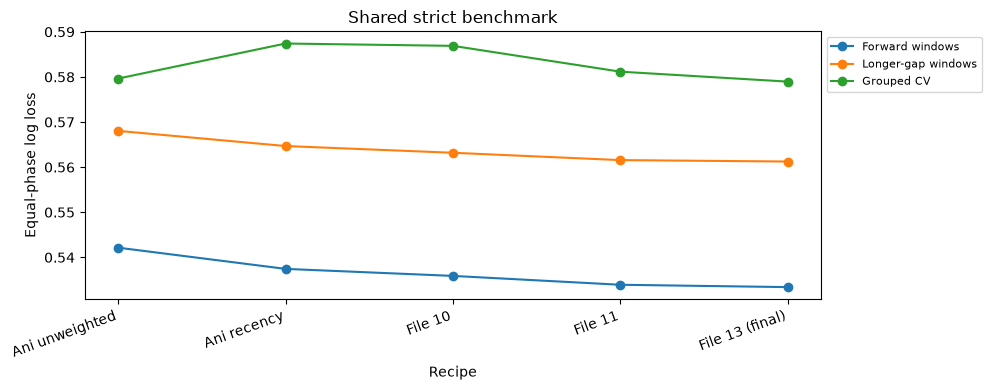

In [3]:
chosen = ["ani_first", "ani_stack", "file10", "mix_legacy01_0.2", "mix_legacy01_0.3"]
columns = ["official", "temporal", "worst", "cv", "gap_mean", "gap_worst"]
comparisons = {}
for track in ["strict", "published"]:
    table = pd.read_csv(SPRINT / f"summary_{track}.csv").set_index("model")
    comparisons[track] = table.loc[chosen, columns]
    display(Markdown(f"### {track.title()} preprocessing"))
    display(comparisons[track])
comparisons["strict"].to_csv(GENERATED / "common_benchmark.csv")
plotted = comparisons["strict"][["temporal", "gap_mean", "cv"]].rename(
    index={"ani_first": "Ani unweighted", "ani_stack": "Ani recency", "file10": "File 10",
           "mix_legacy01_0.2": "File 11", "mix_legacy01_0.3": "File 13 (final)"},
    columns={"temporal": "Forward windows", "gap_mean": "Longer-gap windows", "cv": "Grouped CV"})
ax = plotted.plot(marker="o", figsize=(10, 4))
ax.set(ylabel="Equal-phase log loss", xlabel="Recipe", title="Shared strict benchmark")
ax.set_xticks(range(len(plotted)), plotted.index, rotation=20, ha="right")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(GENERATED / "common_benchmark.png", dpi=160, bbox_inches="tight")
plt.show()


## Verify the main comparisons from row-level predictions

The following check recomputes every phase log loss on each of the ten original
splits for the five recipes above, in both preprocessing tracks. It also checks
split membership and original labels. The longer-gap results and paired
uncertainty estimates remain in the linked phase reports.

In [4]:
from benchmark_protocol import initialize, resolve
universe, protocol = initialize()
verification_rows = []
for track in ["strict", "published"]:
    for split in protocol["splits"]:
        _, evaluation = resolve(universe, split)
        stored = pd.read_csv(SPRINT / track / f"scores_{split['name']}.csv").set_index("model")
        for model in chosen:
            frame = pd.read_csv(SPRINT / track / "predictions" / split["name"] / f"{model}.csv")
            assert frame[["ID", "trial_id", "phase", "label"]].equals(evaluation[["ID", "trial_id", "phase", "label"]])
            measured = metrics(evaluation, frame.probability.to_numpy())
            for phase in PHASES:
                assert abs(measured[phase+"_logloss"] - stored.loc[model, phase+"_logloss"]) < 1e-12
            assert abs(measured["phase_mean_logloss"] - stored.loc[model, "phase_mean_logloss"]) < 1e-12
            verification_rows.append(dict(track=track, split=split["name"], model=model,
                                          phase_mean_logloss=measured["phase_mean_logloss"]))
verified = pd.DataFrame(verification_rows)
assert len(verified) == 100
verified.to_csv(GENERATED / "benchmark_rescoring.csv", index=False)
print(f"Verified {len(verified)} recipe/split/track evaluations against original row labels.")


Verified 100 recipe/split/track evaluations against original row labels.


## Kaggle feedback and final decision

Only confirmed submitted artifacts have recorded scores. Local recipes and
unsubmitted reserves do not inherit scores from similar filenames or weights.
These are historical team records and commit messages; no live leaderboard was queried.

,model,kaggle_log_loss,source
0,ani_first,0.58810,Kaggle score recorded in Ani's commit history
1,ani_stack,0.58688,Kaggle score recorded in Ani's commit history
2,03_phase_specialized.csv,0.59562,Kaggle result recorded by our team
3,02_text_heavy.csv,0.58993,Kaggle result recorded by our team
4,10_ani_fast2_neighbors_half.csv,0.58609,Kaggle result recorded by our team
5,11_file10_legacy20.csv,0.58474,Kaggle result recorded by our team
6,13_file10_legacy30.csv,0.58465,Kaggle result recorded by our team
7,15_file10_legacy20_tree10_trend10.csv,0.58492,Kaggle result recorded by our team


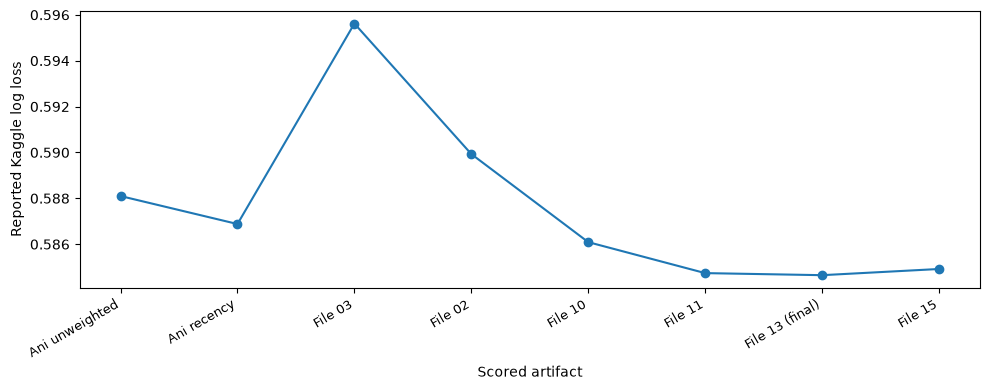

{'status': 'Hold final slot; file 16 remains unsubmitted',
 'reviewed_at_utc': '2026-11-06T23:50:30.004149+00:00',
 'supersedes_upload_recommendation': 'final_selection.json',
 'best_file': '13_file10_legacy30.csv',
 'best_score': 0.58465,
 'reason': 'We confirmed first place with nine total submissions. Reconsideration of final-slot value: file 16 has small chronological gains, slightly worse grouped CV and uncertainty intervals spanning zero; file 15 already failed to transfer. One aggregate score would leave no slot for follow-up. The earlier exploratory upload recommendation is withdrawn.',
 'remaining_uploads': 1,
 'actual_score_for_file16': None}

In [5]:
rows = []
for name, item in ledger["ani_winners"].items():
    rows.append(dict(model=name, kaggle_log_loss=item["kaggle_score"], source="Kaggle score recorded in Ani's commit history"))
for name, item in ledger["submissions"].items():
    assert sha256(ROOT / "submissions" / name) == item["sha256"]
    rows.append(dict(model=name, kaggle_log_loss=item["kaggle_score"], source="Kaggle result recorded by our team"))
feedback = pd.DataFrame(rows)
display(feedback)
feedback.to_csv(GENERATED / "kaggle_feedback.csv", index=False)
ax = feedback.set_index("model").kaggle_log_loss.plot(marker="o", figsize=(10, 4))
ax.set(ylabel="Reported Kaggle log loss", xlabel="Scored artifact")
labels = ["Ani unweighted", "Ani recency", "File 03", "File 02", "File 10", "File 11", "File 13 (final)", "File 15"]
ax.set_xticks(range(len(feedback)), labels, rotation=30, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig(GENERATED / "kaggle_progress.png", dpi=160, bbox_inches="tight")
plt.show()
decision = json.loads((ROOT / "experiments/leaderboard_sprint/refine/2e5c792462013673/submission_decision.json").read_text())
decision["reason"] = 'We confirmed first place with nine total submissions. Reconsideration of final-slot value: file 16 has small chronological gains, slightly worse grouped CV and uncertainty intervals spanning zero; file 15 already failed to transfer. One aggregate score would leave no slot for follow-up. The earlier exploratory upload recommendation is withdrawn.'
display(decision)


## Re-running research versus reproducing the final model

The final model's fresh training is in notebook 01. The complete historical
research suite is much larger and is not rerun by default. Its original
notebooks, saved notebook outputs, settings and trial summary tables are
included in `resources/`. Their execution may require regenerating omitted
intermediate arrays or using the full working checkout. Use the commands in
[reproduction instructions](resources/docs/CACHE_REPRODUCTION.md) and
[organization guide](resources/docs/ORGANIZATION.md), replacing `part2/`
with this package's `resources/` path. Rebuild omitted intermediate predictions
and fitted caches first; some historical runners expect earlier phases to
have completed. The full working project retains those intermediates.

Historical scripts that recreate Part 1 reason labels require the separate
Part 1 project. The supplied frozen labels fully reproduce Part 2 post-hoc
analysis without that step. Historical Git-based provenance/tag checks also
require the research Git repository; the hand-in uses file hashes instead.